In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv("../data/bnr_rates.csv",index_col="date",parse_dates=True)
df.tail()

,EUR,USD
date,,
2026-09-29,5.2780,4.6568
2026-09-30,5.2785,4.6474
2026-10-01,5.2777,4.6765
2026-10-02,5.3447,4.7519
2026-10-05,5.3306,4.7569


In [4]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2950 entries, 2015-01-05 to 2026-10-05
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   EUR     2950 non-null   float64
 1   USD     2950 non-null   float64
dtypes: float64(2)
memory usage: 69.1 KB


In [6]:
df.describe()

,EUR,USD
count,2950.000000,2950.000000
mean,4.803327,4.287500
std,0.220314,0.279430
min,4.396500,3.717000
25%,4.628225,4.058250
50%,4.870600,4.269650
75%,4.968200,4.519575
max,5.344700,5.179400


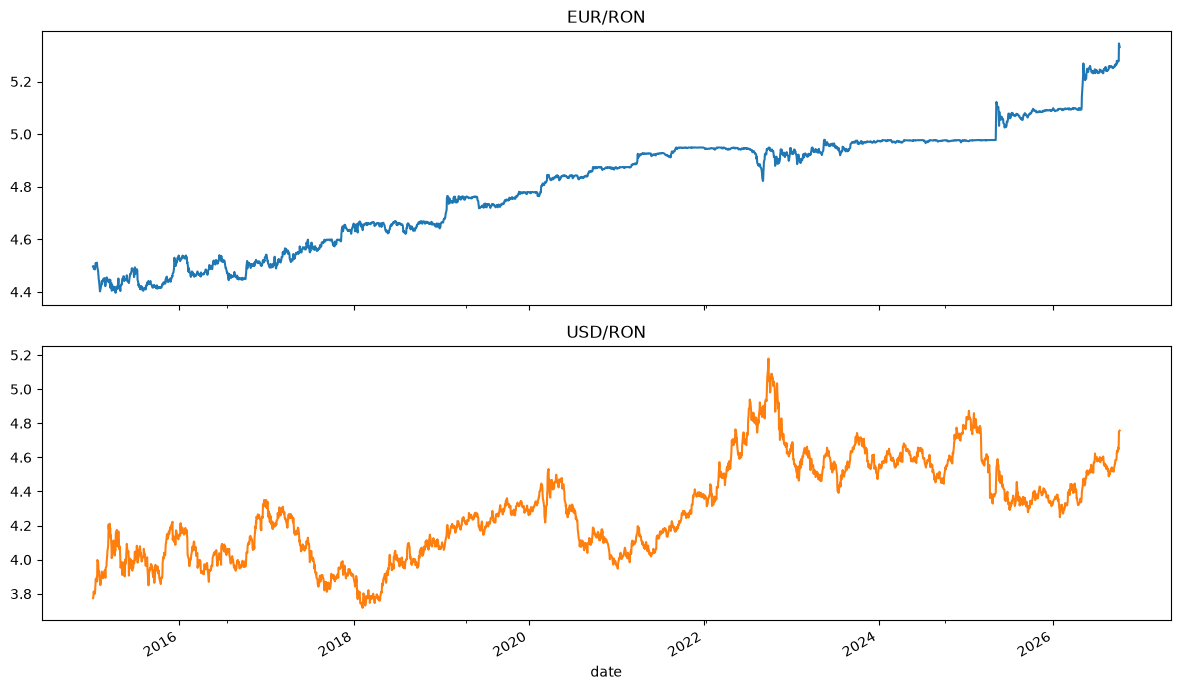

In [8]:
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
df['EUR'].plot(ax=axes[0],title="EUR/RON",color="tab:blue")
df["USD"].plot(ax=axes[1],title="USD/RON",color="tab:orange")
plt.tight_layout()
plt.show()

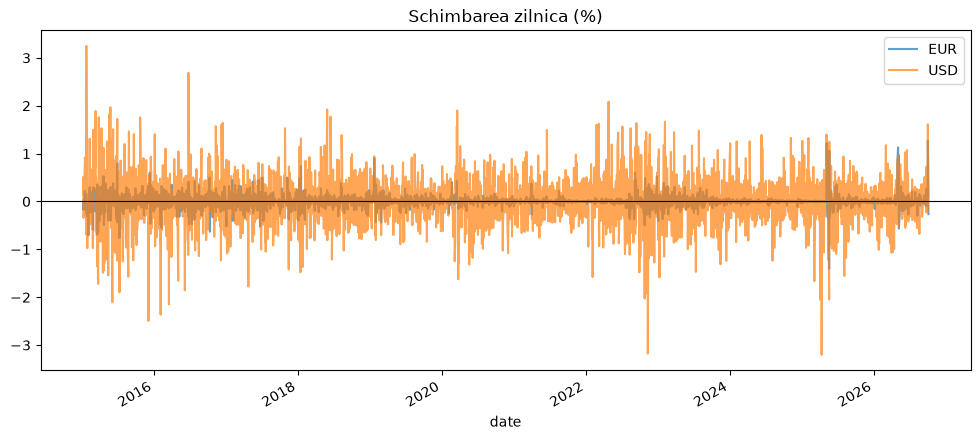

,EUR,USD
count,2949.000000,2949.000000
mean,0.005852,0.009170
std,0.132309,0.514333
min,-1.406933,-3.204545
25%,-0.031653,-0.264987
50%,0.002009,0.009416
75%,0.040239,0.283374
max,1.269492,3.251466


In [10]:
returns= df.pct_change()*100
returns.plot(figsize=(12,5), title="Schimbarea zilnica (%)",alpha=0.7)
plt.axhline(0,color="black",linewidth=0.8)
plt.show()

returns.describe()

In [12]:
up_days=(returns>0).mean()*100
print("Procent zile de crestere:")
print(up_days.round(1))

Procent zile de crestere:
EUR    50.6
USD    50.7
dtype: float64


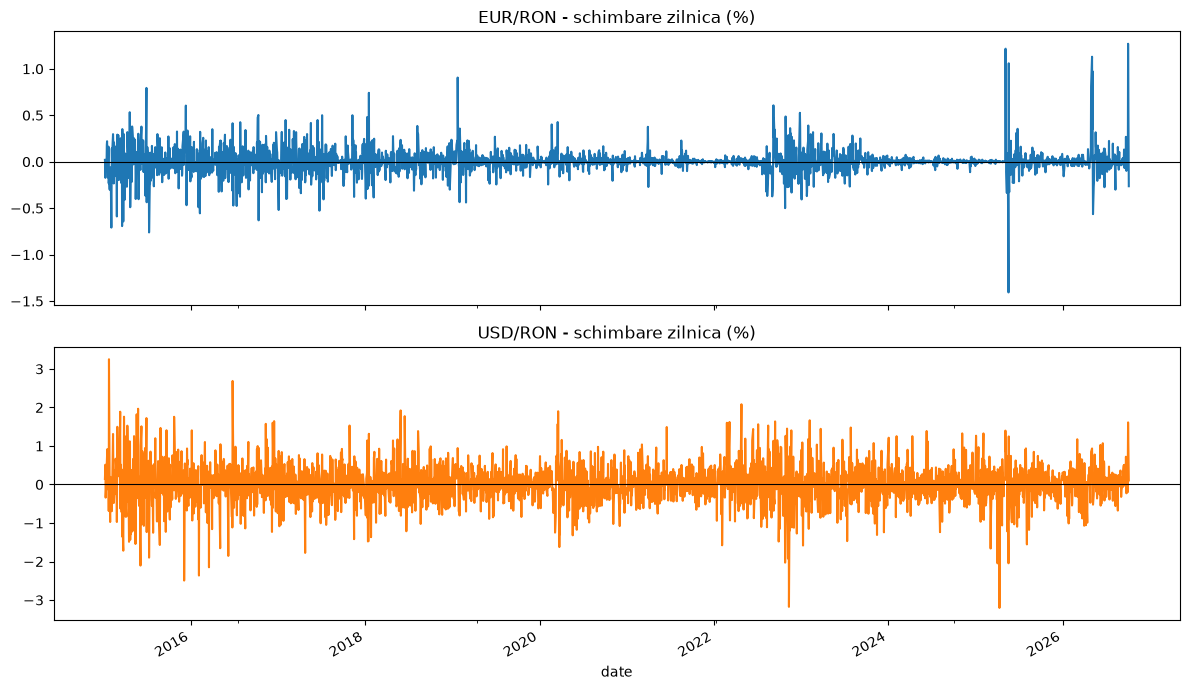

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
returns["EUR"].plot(ax=axes[0], title="EUR/RON - schimbare zilnica (%)", color="tab:blue")
returns["USD"].plot(ax=axes[1], title="USD/RON - schimbare zilnica (%)", color="tab:orange")
for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [15]:
top= returns["EUR"].abs().sort_values(ascending=False).head(15)
print(returns.loc[top.index, "EUR"].round(2))

date
2025-05-19   -1.41
2026-10-02    1.27
2025-05-07    1.22
2025-05-06    1.21
2026-05-04    1.13
2025-05-20    1.06
2026-05-06    0.97
2019-01-23    0.91
2026-04-30    0.81
2015-06-29    0.79
2015-07-10   -0.76
2018-01-16    0.74
2015-02-02   -0.71
2015-03-19   -0.69
2015-03-24   -0.64
Name: EUR, dtype: float64
